# Лабораторная № 3. Оптимизация гиперпараметров
**Темников Дмитрий Павлович, М8О-306БВ-24, № 26 в списке**

Сравним два способа подбора параметров дерева решений из лабораторной № 2. Задача — предсказать `Survived` по данным Titanic: 1 — выжил, 0 — погиб.

Для запуска нужны `pandas`, `matplotlib` и `scikit-learn`. CSV уже лежит в `classification/data`.

## 1. Данные и исходная модель

Оставляем те же признаки и то же стратифицированное разбиение 80/20, что в ЛР № 2. Номер 26 используем как `random_state`. Убираем имя, ID, билет и почти пустой столбец с каютой. Числовые пропуски заполняем медианой, категориальные — модой, затем кодируем категории с помощью One-Hot. Эти операции входят в `Pipeline` и обучаются заново на обучающей части каждого фолда.

Baseline — дерево из ЛР № 2: `max_depth=4`, `min_samples_leaf=5`, `criterion='gini'`. Метрика — **F1 класса 1**: гармоническое среднее точности и полноты для выживших. Чем выше, тем лучше.

В ЛР № 2 это дерево получило CV F1 = 0.694 на трёх фолдах и Test F1 = 0.750. Для сравнения методов в этой работе заново считаем CV F1 исходного дерева на тех же пяти фолдах, что и для новых настроек.

In [35]:
%matplotlib inline
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import f1_score
from sklearn.model_selection import (
    GridSearchCV, ParameterGrid, RandomizedSearchCV, StratifiedKFold, cross_val_score, train_test_split,
)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

SEED = 26
csv = Path('classification/data/Titanic-Dataset.csv')
paths = [Path('..') / csv, csv, Path('ml_course_mai') / csv]
data = pd.read_csv(next((p for p in paths if p.is_file()), paths[0]))
X = data.drop(columns=['Survived', 'PassengerId', 'Name', 'Ticket', 'Cabin'])
y = data['Survived']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED,
)
display(pd.Series({'Train': len(X_train), 'Test': len(X_test)}, name='Пассажиров'))

prep = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), ['Age', 'SibSp', 'Parch', 'Fare']),
    ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
                          OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
     ['Pclass', 'Sex', 'Embarked']),
])
baseline_params = {
    'tree__max_depth': 4,
    'tree__min_samples_leaf': 5,
    'tree__class_weight': None,
}
baseline = Pipeline([('prep', prep), ('tree', DecisionTreeClassifier(random_state=SEED))])
baseline = baseline.set_params(**baseline_params)

Train    712
Test     179
Name: Пассажиров, dtype: int64

## 2. Кросс-валидация

Используем **5 стратифицированных фолдов**: в каждой проверке учимся на четырёх частях train и оцениваем F1 на пятой (около 142 пассажиров). Стратификация сохраняет доли классов. Пять фолдов позволяют проверить модель на разных частях данных при небольших затратах. Для всех настроек разбиения одинаковые.

Одно разбиение даёт оценку, которая зависит от состава проверочной части. Кросс-валидация показывает среднее качество и разброс по нескольким проверкам. Если многократно выбирать параметры по test, можно подстроиться под его случайные особенности, и оценка качества на новых данных станет завышенной.

In [36]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
baseline_folds = cross_val_score(baseline, X_train, y_train, cv=cv, scoring='f1')
display(pd.Series({'CV F1': baseline_folds.mean()}, name='Исходное дерево').round(3))

CV F1    0.707
Name: Исходное дерево, dtype: float64

## 3. Grid Search и Random Search

В первой попытке поиск выбирал более глубокие деревья, а график показывал растущий разрыв между train и CV. Теперь ограничиваем глубину шестью уровнями, убираем листья меньше пяти объектов и проверяем веса классов. Критерий разбиения фиксируем как `gini`, как у исходного дерева.

| Параметр | Смысл и ожидаемый эффект | Диапазон |
|---|---|---|
| `max_depth` | Максимальная глубина дерева. Малая глубина может мешать выучить сочетания признаков, большая повышает риск переобучения. | 1–6 |
| `min_samples_leaf` | Минимальное число пассажиров в листе. Большие листья снижают чувствительность к редким примерам, но могут сгладить полезные закономерности. | 5–30 |
| `class_weight` | Вес классов при построении дерева. `None` даёт всем пассажирам одинаковый вес, `balanced` повышает вес менее частого класса «выжил». Полнота класса 1 может вырасти, а точность снизиться. | `None`, `balanced` |

Grid Search проверяет все **48 комбинаций** сетки. Random Search проверяет столько же разных комбинаций в тех же границах, но может взять промежуточные размеры листа. У каждого поиска **48 × 5 = 240** обучений на фолдах. В таблице замеряем время основного поиска на train. Вложенную проверку и финальное обучение выполняем отдельно.

In [37]:
grid_params = {
    'tree__max_depth': [1, 2, 3, 4, 5, 6],
    'tree__min_samples_leaf': [5, 10, 20, 30],
    'tree__class_weight': [None, 'balanced'],
}
random_params = {
    'tree__max_depth': grid_params['tree__max_depth'],
    'tree__min_samples_leaf': list(range(5, 31)),
    'tree__class_weight': grid_params['tree__class_weight'],
}
n_candidates = len(list(ParameterGrid(grid_params)))
search_options = dict(cv=cv, scoring='f1', refit=False, return_train_score=True)
searches = {
    'Grid Search': GridSearchCV(baseline, grid_params, **search_options),
    'Random Search': RandomizedSearchCV(
        baseline, random_params, n_iter=n_candidates, random_state=SEED, **search_options,
    ),
}

search_rows = {}
for name, search in searches.items():
    start = perf_counter()
    search.fit(X_train, y_train)
    elapsed = perf_counter() - start
    search_rows[name] = {
        'Комбинаций': len(search.cv_results_['params']),
        'CV F1': search.best_score_,
        'Время, с': elapsed,
        'Глубина': search.best_params_['tree__max_depth'],
        'Мин. размер листа': search.best_params_['tree__min_samples_leaf'],
        'Веса классов': str(search.best_params_['tree__class_weight']),
    }
display(pd.DataFrame.from_dict(search_rows, orient='index').round(3))

,Комбинаций,CV F1,"Время, с",Глубина,Мин. размер листа,Веса классов
Grid Search,48,0.757,2.870,4,5,balanced
Random Search,48,0.756,2.662,4,12,balanced


На фолдах поиска Grid Search получил F1 **0.757**, Random Search — **0.756**. Оба использовали по 48 комбинаций и заняли сопоставимое время. Если параметров много, число комбинаций сетки быстро растёт. Случайный поиск позволяет заранее ограничить число проверок и попробовать больше промежуточных значений.

## 4. Как параметры влияют на F1

Для каждого графика меняем один параметр, а два остальных оставляем как в исходном дереве. Используем уже посчитанные результаты Grid Search. Train F1 — качество на обучающих частях фолдов, CV F1 — на проверочных.

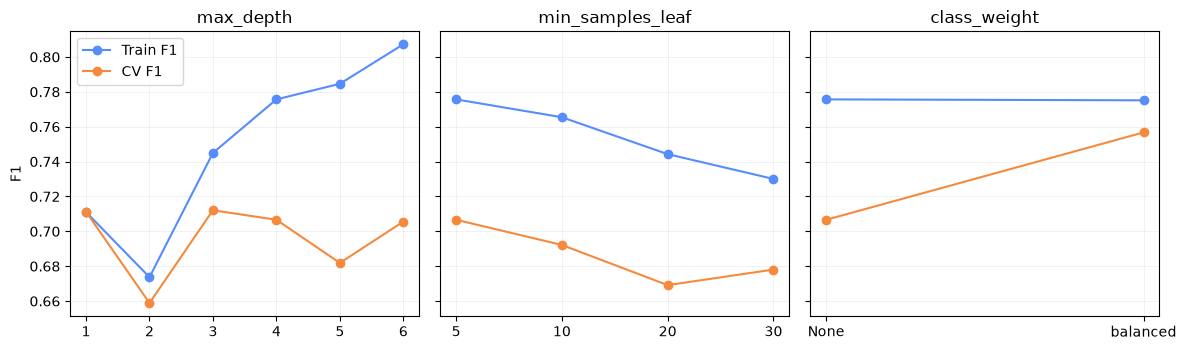

In [38]:
grid_results = pd.DataFrame(searches['Grid Search'].cv_results_)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, param in zip(axes, grid_params):
    subset = grid_results
    for other, value in baseline_params.items():
        if other == param:
            continue
        column = subset[f'param_{other}']
        matches = column.isna() if value is None else column.eq(value)
        subset = subset[matches]

    column = f'param_{param}'
    values = grid_params[param]
    rows = []
    for value in values:
        matches = subset[column].isna() if value is None else subset[column].eq(value)
        rows.append(subset.loc[matches].iloc[0])
    points = pd.DataFrame(rows)
    ticks = range(len(values))
    ax.plot(ticks, points['mean_train_score'], 'o-', label='Train F1')
    ax.plot(ticks, points['mean_test_score'], 'o-', label='CV F1')
    ax.set(title=param.removeprefix('tree__'), xticks=ticks, xticklabels=map(str, values))
    ax.grid(alpha=0.25)
axes[0].set_ylabel('F1')
axes[0].legend()
plt.tight_layout()
plt.show()

- При минимальном размере листа 30 падают Train F1 и CV F1. Слишком большие листья могут привести к недообучению.
- Глубина 4 и минимум 5 объектов в листе оставляют дереву достаточно свободы. При увеличении глубины Train F1 растёт быстрее, чем CV F1. Растущий разрыв указывает на риск переобучения.
- При глубине 4 и минимуме 5 объектов в листе балансировка классов повышает CV F1 с 0.707 до 0.757.

## 5. Устойчивость и выбор модели

В таблице поиска показаны лучшие оценки на тех же фолдах, по которым выбирались параметры. Чтобы оценить весь процесс подбора, используем **вложенную кросс-валидацию 5 × 5**. На каждой итерации оставляем один внешний фолд для проверки. Каждый поиск подбирает параметры на остальных данных по пяти внутренним фолдам и переобучает выбранное дерево на внешней обучающей части. Затем считаем F1 на отложенном внешнем фолде. Исходное дерево оцениваем на тех же внешних фолдах.

Стандартное отклонение (σ) показывает, насколько оценки расходятся между фолдами. Две модели могут иметь одинаковое среднее, но одна лучше переносит изменения в составе проверочных данных.

In [39]:
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
outer_scores = {'Исходное дерево': baseline_folds}
for name, search in searches.items():
    procedure = clone(search).set_params(refit=True, return_train_score=False)
    outer_scores[name] = cross_val_score(procedure, X_train, y_train, cv=outer_cv, scoring='f1')

folds = pd.DataFrame(outer_scores, index=[f'Фолд {i}' for i in range(1, outer_cv.n_splits + 1)]).T
cv_summary = folds.assign(**{'Внешняя CV F1': folds.mean(axis=1), 'σ': folds.std(axis=1, ddof=0)})
display(cv_summary.round(3))
winner = cv_summary['Внешняя CV F1'].idxmax()
display(f'Выбор по внешней CV: {winner}')

,Фолд 1,Фолд 2,Фолд 3,Фолд 4,Фолд 5,Внешняя CV F1,σ
Исходное дерево,0.755,0.827,0.632,0.729,0.591,0.707,0.085
Grid Search,0.748,0.810,0.785,0.741,0.681,0.753,0.044
Random Search,0.748,0.750,0.705,0.741,0.681,0.725,0.027


'Выбор по внешней CV: Grid Search'

Grid Search получил наибольшее среднее F1 (0.753), поэтому выбираем его для финального сравнения. У Random Search разброс меньше (σ = 0.027 против 0.044), но и средний F1 ниже (0.725). У исходного дерева оценки колеблются от 0.591 до 0.827.

## 6. Финальная проверка

Для каждого поиска берём настройки, подобранные на всём train в разделе 3, и обучаем дерево на полном train. Затем оцениваем все три дерева на тех же 179 пассажирах, что и в прошлой версии. Этот test уже использовался ранее, поэтому его результат служит повторной проверкой. Оценку процесса подбора берём из внешней CV.

In [40]:
models = {'Исходное дерево': baseline}
for name, search in searches.items():
    models[name] = clone(baseline).set_params(**search.best_params_)

test_scores = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    test_scores[name] = f1_score(y_test, model.predict(X_test))

results = cv_summary[['Внешняя CV F1']].assign(**{'Test F1': pd.Series(test_scores)})
results['Δ внешняя CV F1'] = results['Внешняя CV F1'] - results.loc['Исходное дерево', 'Внешняя CV F1']
results['Δ Test F1'] = results['Test F1'] - results.loc['Исходное дерево', 'Test F1']
display(results.round(3))

,Внешняя CV F1,Test F1,Δ внешняя CV F1,Δ Test F1
Исходное дерево,0.707,0.750,0.000,0.000
Grid Search,0.753,0.743,0.046,-0.007
Random Search,0.725,0.719,0.018,-0.031


### Вывод

Grid Search выбрал глубину 4, минимум 5 объектов в листе. На внешней кросс-валидации его F1 вырос с **0.707 до 0.753** (+0.046), у Random Search — до **0.725** (+0.018).

На прежнем test Grid Search получил **0.743**. Это лучше первой попытки (0.677), но ниже исходного дерева (**0.750**). У Random Search Test F1 равен **0.719**. Различия между внешней CV и test могут зависеть от состава выборок. На конкретном тестовом наборе ни один поиск не обошёл исходное дерево.